In [177]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')



In [178]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("dgomonov/new-york-city-airbnb-open-data")

print("Path to dataset files:", path)

df = pd.read_csv(os.path.join(path, "AB_NYC_2019.csv"))
df.head()

Using Colab cache for faster access to the 'new-york-city-airbnb-open-data' dataset.
Path to dataset files: /kaggle/input/new-york-city-airbnb-open-data


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [179]:
df.shape

(48895, 16)

In [180]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [181]:
df.duplicated().sum()

np.int64(0)

In [182]:
missing=df.isnull().sum()
missing [missing > 0 ]

,0
name,16
host_name,21
last_review,10052
reviews_per_month,10052


In [183]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [184]:
df['room_type'].value_counts()

,count
room_type,
Entire home/apt,25409
Private room,22326
Shared room,1160


<Axes: xlabel='room_type', ylabel='count'>

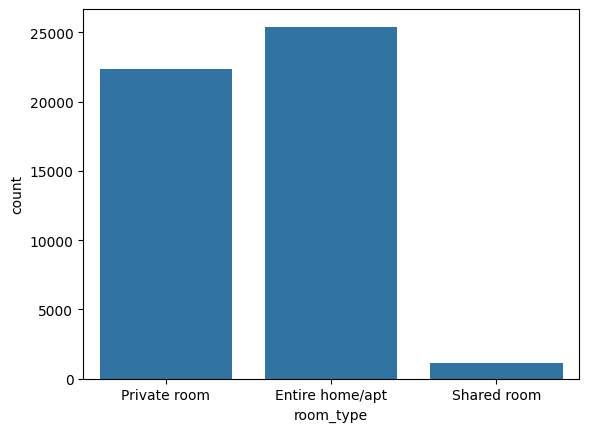

In [185]:
sns.countplot(x='room_type',data=df)
#check class imbalance bht important hai

In [186]:
numeric_col=[  'price', 'minimum_nights',
       'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365']


array([[<Axes: title={'center': 'price'}>,
        <Axes: title={'center': 'minimum_nights'}>],
       [<Axes: title={'center': 'number_of_reviews'}>,
        <Axes: title={'center': 'reviews_per_month'}>],
       [<Axes: title={'center': 'calculated_host_listings_count'}>,
        <Axes: title={'center': 'availability_365'}>]], dtype=object)

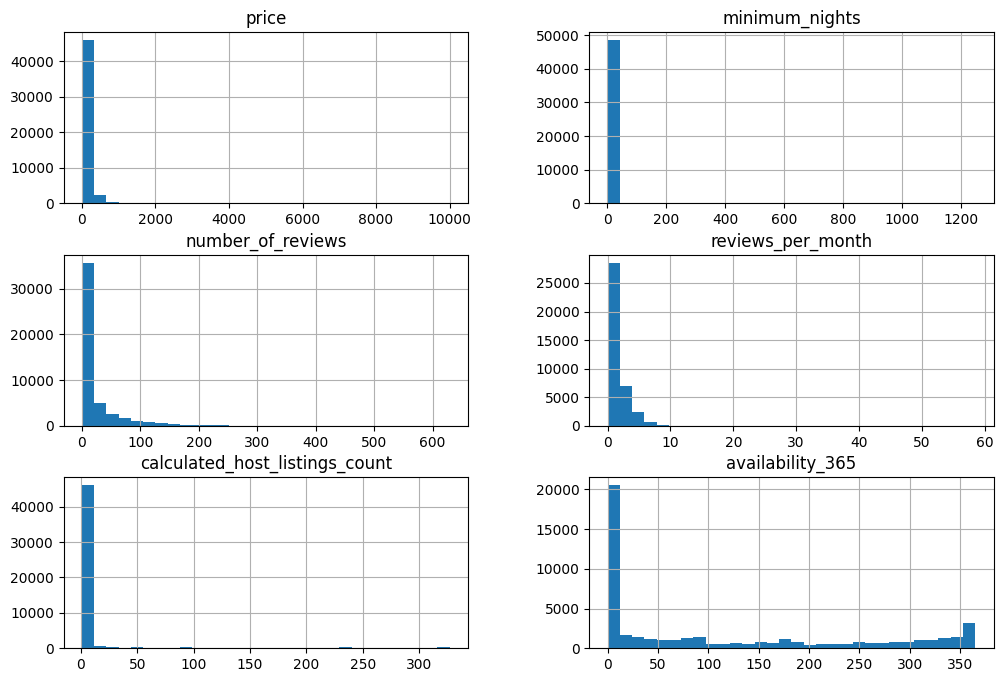

In [187]:
df[numeric_col].hist(bins=30,figsize=(12,8))

<Axes: xlabel='neighbourhood_group', ylabel='count'>

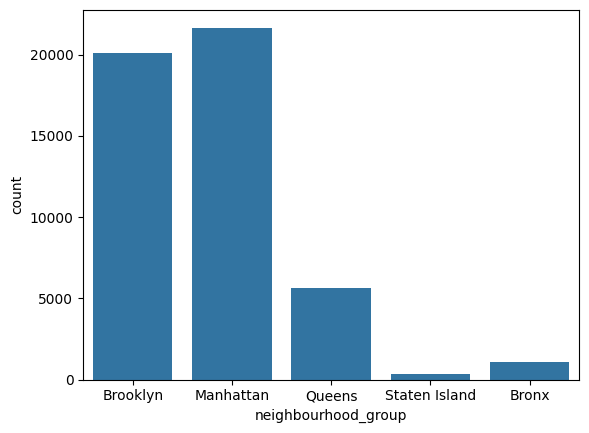

In [188]:
sns.countplot(data=df,x='neighbourhood_group')

<Axes: xlabel='room_type', ylabel='price'>

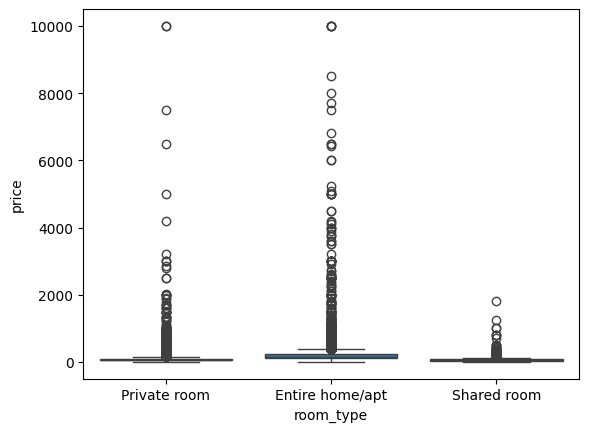

In [189]:
sns.boxplot(data=df,x='room_type',y='price')

In [190]:
corr=df[numeric_col+['latitude','longitude']].corr()
corr

,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,latitude,longitude
price,1.000000,0.042799,-0.047954,-0.030608,0.057472,0.081829,0.033939,-0.150019
minimum_nights,0.042799,1.000000,-0.080116,-0.121702,0.127960,0.144303,0.024869,-0.062747
number_of_reviews,-0.047954,-0.080116,1.000000,0.549868,-0.072376,0.172028,-0.015389,0.059094
reviews_per_month,-0.030608,-0.121702,0.549868,1.000000,-0.009421,0.185791,-0.010142,0.145948
calculated_host_listings_count,0.057472,0.127960,-0.072376,-0.009421,1.000000,0.225701,0.019517,-0.114713
availability_365,0.081829,0.144303,0.172028,0.185791,0.225701,1.000000,-0.010983,0.082731
latitude,0.033939,0.024869,-0.015389,-0.010142,0.019517,-0.010983,1.000000,0.084788
longitude,-0.150019,-0.062747,0.059094,0.145948,-0.114713,0.082731,0.084788,1.000000


<Axes: >

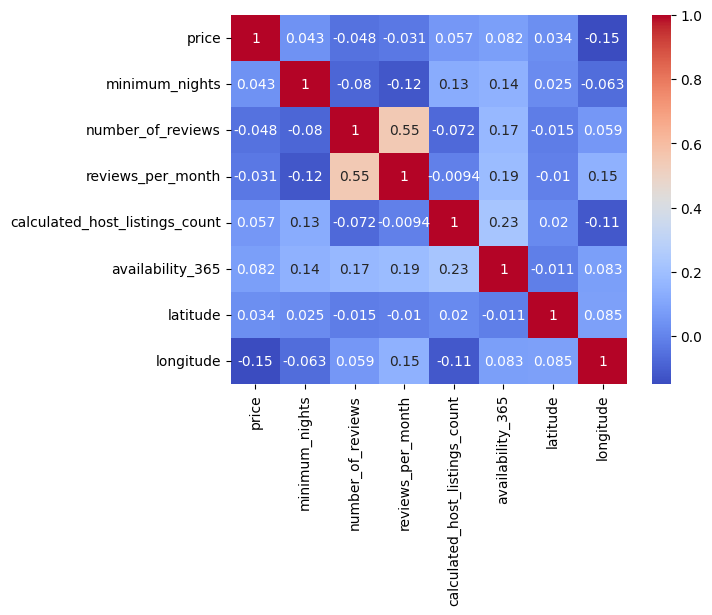

In [191]:
sns.heatmap(corr,annot=True,cmap='coolwarm')

<Axes: xlabel='longitude', ylabel='latitude'>

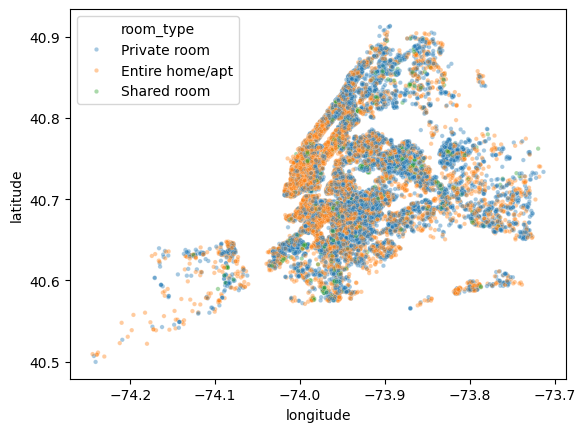

In [192]:
sns.scatterplot(data=df,x='longitude',y='latitude',hue='room_type',alpha=0.4,s=10)

In [193]:
df_clean=df.drop(columns=['name','id','host_id','last_review','host_name'])

In [194]:
df_clean.shape

(48895, 11)

In [195]:
df_clean['reviews_per_month']=df_clean['reviews_per_month'].fillna(0)

In [196]:
df_clean.isnull().sum()

,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0
minimum_nights,0
number_of_reviews,0
reviews_per_month,0
calculated_host_listings_count,0


In [197]:
price_cap=df_clean['price'].quantile(0.99)
nights_cap=df_clean['minimum_nights'].quantile(0.99)
df_clean['price']=df_clean['price'].clip(upper=price_cap)
df_clean['minimum_nights']=df_clean['minimum_nights'].clip(upper=nights_cap)

<Axes: xlabel='room_type', ylabel='price'>

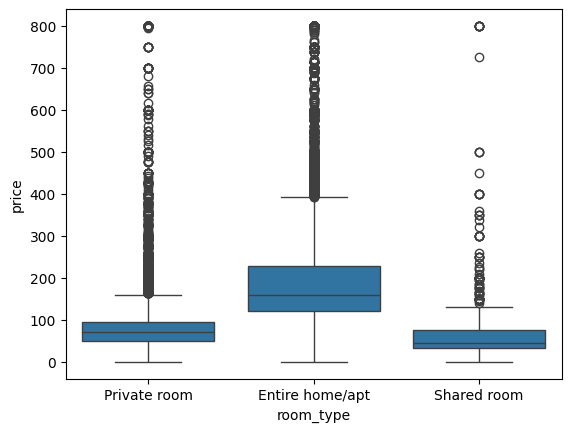

In [198]:
sns.boxplot(data=df_clean,x='room_type',y='price')

In [199]:
X=df_clean.drop(columns='room_type')

In [200]:
y=df_clean['room_type']

In [201]:
from sklearn.model_selection import  train_test_split

In [202]:
X_train,X_test,y_train,y_test=train_test_split(
    X,y
    ,test_size=0.33,
    random_state=42,
    stratify=y

)

In [203]:
#Stratisfy ye ensure krta hai ki jab bhi hum split ya sample kare , har group(class) ka Original Propotion maintain rahe.

In [204]:
numerical_columns=[ 'latitude', 'longitude', 'price', 'minimum_nights',
       'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365']
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder,PowerTransformer
from sklearn.compose import ColumnTransformer

In [205]:
categorical_cols=df_clean.select_dtypes(include=['object']).columns
categorical_cols

Index(['neighbourhood_group', 'neighbourhood', 'room_type'], dtype='object')

In [206]:
cat_cols=['neighbourhood_group', 'neighbourhood']

In [207]:
numeric_pipeline=Pipeline(steps=[
  ('imputer',SimpleImputer(strategy='median')),
  ('scale',StandardScaler())
])

categorical_pipeline=Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='most_frequent')),

    ('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))
])

preprocessor=ColumnTransformer(transformers=[
   ( 'numeric',numeric_pipeline,numerical_columns),
   ('categorical',categorical_pipeline,cat_cols)
])
preprocessor

ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['latitude', 'longitude', 'price',
                                  'minimum_nights', 'number_of_reviews',
                                  'reviews_per_month',
                                  'calculated_host_listings_count',
                                  'availability_365']),
                                ('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encode',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['neighbourhood_group', 'neighbourhood'])])

In [208]:
#target variable mai fixing class imbalance ke liye SMOTE -synthetic minority oversampling
#but smote ki vajah se overfitting ke kafhi high chance hai toh mai class weight use karunga
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

# class weight=balanced means it tells model to pay more attention to the minority class
#or rare class (shared room)
#but the problem is gradient boosting does not support class_weight so we leave it as it is





In [209]:
models={
    "LogisticRegression":LogisticRegression(class_weight="balanced",random_state=42),
    "DecisionTreeClassifier":DecisionTreeClassifier(class_weight="balanced",random_state=42),
    "RandomForestClassifier":RandomForestClassifier(class_weight="balanced",random_state=42),
    "GradientBoostingClassifier":GradientBoostingClassifier()
}
for name,model in models.items():
  pipe=Pipeline(steps=[
         ('preprocessor',preprocessor),
         ('classifier',model)])
  accuracy=cross_val_score(pipe,X_train,y_train,cv=3,scoring='accuracy')
  #accuracy can be misleading on imbalnced class, so we use macro f1 score
  #both:plain accuracy and marco f1 score (which treat every class equally)
  macrof1=cross_val_score(pipe,X_train,y_train,cv=3,scoring='f1_macro')
  print(f"{name}-> Accuracy: {accuracy.mean():.3f},F1:{macrof1.mean():.3f}")


LogisticRegression-> Accuracy: 0.659,F1:0.522
DecisionTreeClassifier-> Accuracy: 0.782,F1:0.651
RandomForestClassifier-> Accuracy: 0.850,F1:0.712
GradientBoostingClassifier-> Accuracy: 0.850,F1:0.705


In [210]:
best_pipeline=Pipeline(steps=[('preprocessor',preprocessor),
                              ('classfier',RandomForestClassifier(class_weight='balanced'))
                              ])

In [211]:
from sklearn.model_selection import RandomizedSearchCV
param_distribution={
    'classfier__n_estimators':[100,200,150,300],
    'classfier__max_depth':[None,8,12,15,20],
    'classfier__min_samples_split':[2,5,10],
}
search=RandomizedSearchCV(estimator=best_pipeline,
                   param_distributions=param_distribution,
                   n_iter=10,
                   cv=3,
                   scoring='f1_macro',
                   random_state=42)
search.fit(X_train,y_train)

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('numeric',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scale',
                                                                                                StandardScaler())]),
                                                                               ['latitude',
                                                                                'longitude',
                                                                                'price',
                                                                                'minimum_nights',
                                                                                'number_of_reviews',
                                                                                'reviews_per_month',
                                                                                'calculated_host_listings_count',
                                                                                'availability_365']),
                                                                              ('catego...
                                                                                                OneHotEncoder(handle_unknown='ignore',
                                                                                                              sparse_output=False))]),
                                                                               ['neighbourhood_group',
                                                                                'neighbourhood'])])),
                                             ('classfier',
                                              RandomForestClassifier(class_weight='balanced'))]),
                   param_distributions={'classfier__max_depth': [None, 8, 12,
                                                                 15, 20],
                                        'classfier__min_samples_split': [2, 5,
                                                                         10],
                                        'classfier__n_estimators': [100, 200,
                                                                    150, 300]},
                   random_state=42, scoring='f1_macro')

In [213]:
best_para=search.best_params_
best_para

{'classfier__n_estimators': 200,
 'classfier__min_samples_split': 10,
 'classfier__max_depth': 20}

In [214]:
best_cv_macrof1=search.best_score_
best_cv_macrof1

np.float64(0.7279762482992599)

In [220]:
from sklearn.metrics import accuracy_score,confusion_matrix,f1_score
best_pipeline=search.best_estimator_
best_pipeline.predict(X_test)
y_pred=best_pipeline.predict(X_test)
print(f"Accuracy:{accuracy_score(y_test,y_pred)}")
print(f"F1 Score:{f1_score(y_test,y_pred,average='macro')}")


Accuracy:0.8484134853743183
F1 Score:0.7413572894872176


<Axes: >

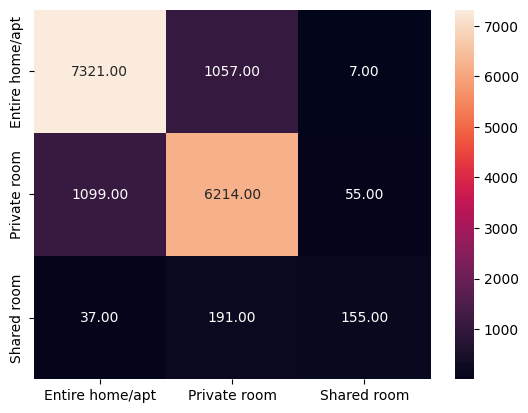

In [222]:
sns.heatmap(confusion_matrix(y_test,y_pred),annot=True,fmt=".2f",
            xticklabels=best_pipeline.classes_,yticklabels=best_pipeline.classes_)

In [223]:
import joblib
joblib.dump(best_pipeline,"Model_pipeline.pkl")

['Model_pipeline.pkl']